# Exp16 — Residual-stream patching at depth

**Question.** For IOI, do the residual-stream representations stay shared across languages as depth increases, or do they dissociate somewhere in the stack?

**Method.** Patch the full residual vector at the end of layer `L` in a target-language forward pass with the matched EN donor activation (final token position). Measure target-language IOI logit-diff recovery. Sweep `L` across the whole stack.

**Expectation if representations dissociate with scale.** Shallow `L` recovers (shared early), deep `L` fails. "Depth of split" (shallowest `L` where cross compat drops below 0.5) gets shallower at larger scales — i.e. more of the stack is language-specific at 27B than at 2B.

**Scope.**
- Models: Gemma-2 2B base, 9B base, 9B-it, 27B-it.
- Donor: EN. Targets: FR (close), DE (close), HI (typologically distant).
- Task: IOI only. Agreement / arithmetic / factual recall are separate experiments.
- Matched-prompt condition: EN names in target templates (same names, same order, position-i is the matched pair).

**Controls that are not optional.**
1. **Self-test.** EN prompt patched with its own captured residual → compat ≈ 1.0 at every tested depth. If any fails, **STOP** — the hook is broken.
2. **Floor control.** Same-language different-template donor → compat ≈ 1.0 at every `L`. If floor fails at some `L`, the cross compat at that `L` is uninterpretable; the row is flagged **UNTRUSTED**.
3. **Baseline accuracy ≥ 0.75** on the target language with EN names, per scale, before any patching curve for that scale is interpreted.

Run top-to-bottom through **RUN 1** (2B only), inspect the summary + plots, consult the decision rules, **then** trigger **RUN 2** (9B base, 9B-it, 27B-it).

## Environment & paths

In [1]:
import os
# CUDA_VISIBLE_DEVICES must be set BEFORE importing torch (project convention: GPU 2 on sentinel).
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import gc, json, random, time, warnings
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_grad_enabled(False)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16

print(f"torch={torch.__version__}  device={DEVICE}  dtype={DTYPE}")
if torch.cuda.is_available():
    gib = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"gpu: {torch.cuda.get_device_name(0)}  mem={gib:.1f} GiB")

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch=2.11.0+cu130  device=cuda  dtype=torch.bfloat16
gpu: NVIDIA H200 NVL  mem=139.8 GiB


In [2]:
MODEL_SPECS = {
    "2b_base":  "google/gemma-2-2b",       # local folder not present on this box; HF hub id
    "9b_base":  "/home/models/gemma-2-9b",
    "9b_it":    "/home/models/gemma-2-9b-it",
    "27b_it":   "/home/models/gemma-2-27b-it",
}

SEEDS        = [0, 7, 13]           # Exp13 / 14 convention
N_PROMPTS    = 120
TARGET_LANGS = ["fr", "de", "hi"]

RESULTS_DIR = Path("exp16_results")
RESULTS_DIR.mkdir(exist_ok=True)
EXP14_DIR   = Path("exp14_results")   # read-only; consulted only if present

print(f"results dir: {RESULTS_DIR.resolve()}")
print(f"exp14 cache dir (optional): {EXP14_DIR.resolve()}  exists={EXP14_DIR.exists()}")

results dir: /home/anwoy/exp16_results
exp14 cache dir (optional): /home/anwoy/exp14_results  exists=True


## Prompts & templates

**Names.** 20 EN proper names, verified single-token under the loaded tokenizer at prompt-build time. Names not single-token are dropped and the drop count is printed.

**Templates.** 6 per language, structurally matched. EN templates end with `to`, FR with `à`, DE with `an` / `zu` so the next token is the recipient name. HI follows the standard SOV pattern ending with the verb, with the recipient name as the natural next token — whether the model can complete this is checked by the baseline-accuracy gate before any curve is interpreted.

**Matched condition.** All target prompts carry the SAME EN names in the SAME order as their EN donor (position-`i` is the matched pair). This neutralizes lexical disjointness so any depth-dependent dissociation reflects *representation*, not vocabulary. This is the Exp14 convention; do not change it in this notebook.

**Floor control pairing.** For each cross pair the floor donor is the SAME names in a DIFFERENT target-language template (template index shifted by one). Both prompts in a floor pair are the target language; capturing from one and patching into the other should give compat ≈ 1.0 at every `L` — if it does not, the method is not passing its own sanity there and that depth's cross number is uninterpretable.

In [3]:
# EN single-token proper names (Exp13 / Exp14 inventory).
EN_NAMES = [
    "John", "Mary", "Michael", "Jennifer", "David",
    "Linda", "James", "Patricia", "Robert", "Susan",
    "Thomas", "Karen", "Daniel", "Sarah", "Mark",
    "Nancy", "Paul", "Laura", "George", "Rachel",
]

In [4]:
EN_TEMPLATES = [
    "When {A} and {B} went to the store, {A} gave a drink to",
    "After {A} and {B} finished their work, {A} handed the keys to",
    "At the park, {A} and {B} were playing, then {A} tossed the ball to",
    "In the office, {A} and {B} were talking, and {A} passed the report to",
    "At the market, {A} and {B} were shopping, so {A} gave the money to",
    "During the meeting, {A} and {B} were sitting, and {A} slid the paper to",
]

FR_TEMPLATES = [
    "Quand {A} et {B} sont allés au magasin, {A} a donné une boisson à",
    "Après que {A} et {B} ont fini leur travail, {A} a remis les clés à",
    "Au parc, {A} et {B} jouaient, puis {A} a lancé le ballon à",
    "Au bureau, {A} et {B} discutaient, et {A} a passé le rapport à",
    "Au marché, {A} et {B} faisaient leurs courses, donc {A} a donné l'argent à",
    "Pendant la réunion, {A} et {B} étaient assis, et {A} a glissé le papier à",
]

DE_TEMPLATES = [
    "Als {A} und {B} zum Laden gingen, gab {A} ein Getränk an",
    "Nachdem {A} und {B} ihre Arbeit beendet hatten, reichte {A} die Schlüssel an",
    "Im Park spielten {A} und {B}, dann warf {A} den Ball zu",
    "Im Büro sprachen {A} und {B}, und {A} gab den Bericht weiter an",
    "Auf dem Markt kauften {A} und {B} ein, also gab {A} das Geld an",
    "Während des Treffens saßen {A} und {B}, und {A} schob das Papier zu",
]

HI_TEMPLATES = [
    "जब {A} और {B} दुकान पर गए, तो {A} ने एक पेय दिया",
    "{A} और {B} ने काम खत्म किया, फिर {A} ने चाबियाँ दीं",
    "बाग में {A} और {B} खेल रहे थे, तब {A} ने गेंद फेंकी",
    "दफ्तर में {A} और {B} बात कर रहे थे, और {A} ने रिपोर्ट दी",
    "बाजार में {A} और {B} खरीदारी कर रहे थे, इसलिए {A} ने पैसे दिए",
    "मीटिंग के दौरान {A} और {B} बैठे थे, और {A} ने कागज बढ़ाया",
]

TEMPLATES = {"en": EN_TEMPLATES, "fr": FR_TEMPLATES, "de": DE_TEMPLATES, "hi": HI_TEMPLATES}
assert all(len(v) == 6 for v in TEMPLATES.values()), "each language needs 6 templates"

In [5]:
def load_exp14_cache(model_key):
    """Try to load Exp14 head-rankings / prompt cache for this model.
    Defensive: if the file isn\'t there or the schema isn\'t recognized,
    returns None and prints a message so we can ask about the field names
    rather than guessing. This experiment does not depend on it (we build
    prompts fresh), but logging it keeps us honest about provenance."""
    path = EXP14_DIR / f"{model_key}.json"
    if not path.exists():
        print(f"[exp14 cache] not found at {path} — building prompts fresh (OK)")
        return None
    try:
        with open(path) as f:
            data = json.load(f)
        top = list(data.keys())[:12] if isinstance(data, dict) else type(data).__name__
        print(f"[exp14 cache] loaded {path}  top keys/preview: {top}")
        return data
    except Exception as e:
        print(f"[exp14 cache] failed to parse {path}: {e!r} — building fresh")
        return None

In [6]:
def _verify_single_token(tok, names, with_leading_space=True):
    good, bad = [], []
    for n in names:
        form = (" " + n) if with_leading_space else n
        ids = tok.encode(form, add_special_tokens=False)
        if len(ids) == 1:
            good.append((n, ids[0]))
        else:
            bad.append((n, ids))
    return good, bad


def prepare_en_names(tok, verbose=True):
    """Return [(name_str, token_id)] for EN names that are single-token
    under this tokenizer, scored with a leading space (mid-sentence form
    the model will actually emit after `to` / `à` / `an` / `zu`)."""
    good, bad = _verify_single_token(tok, EN_NAMES, with_leading_space=True)
    if bad and verbose:
        print(f"[names] {len(bad)} EN names not single-token under this tokenizer:")
        for n, ids in bad[:5]:
            print(f"   {n!r} -> {ids}")
    if verbose:
        print(f"[names] usable single-token EN names: {len(good)}/{len(EN_NAMES)}")
    if len(good) < 4:
        raise RuntimeError(f"not enough single-token EN names ({len(good)}) to build IOI prompts")
    return good


def build_matched_pairs(tok, target_lang, n_prompts, seed):
    """Build cross-language matched pairs: SAME EN names in SAME order
    appear in both the EN donor prompt and the target-language prompt."""
    good = prepare_en_names(tok, verbose=False)
    rng = random.Random(seed)
    en_tpl, tgt_tpl = TEMPLATES["en"], TEMPLATES[target_lang]
    pairs = []
    for i in range(n_prompts):
        a_name, a_id = rng.choice(good)
        b_pool = [p for p in good if p[0] != a_name]
        b_name, b_id = rng.choice(b_pool)
        t = i % len(en_tpl)
        pairs.append({
            "en_prompt":     en_tpl[t].format(A=a_name, B=b_name),
            "target_prompt": tgt_tpl[t].format(A=a_name, B=b_name),
            "io_id":         b_id,          # B appears once -> indirect object
            "s_id":          a_id,          # A appears twice -> subject
            "template_idx":  t,
        })
    return pairs


def build_floor_pairs(tok, target_lang, n_prompts, seed):
    """Same-language different-template pairs for the floor control.
    Donor and target are BOTH in target_lang with the SAME EN names, but
    different template indices. Compat at every L should be ~1.0."""
    good = prepare_en_names(tok, verbose=False)
    rng = random.Random(seed + 10_000)   # separate stream from main
    tpl = TEMPLATES[target_lang]
    pairs = []
    for i in range(n_prompts):
        a_name, a_id = rng.choice(good)
        b_pool = [p for p in good if p[0] != a_name]
        b_name, b_id = rng.choice(b_pool)
        t_a = i % len(tpl)
        t_b = (t_a + 1) % len(tpl)   # cycle; always a different template
        pairs.append({
            "donor_prompt":  tpl[t_a].format(A=a_name, B=b_name),
            "target_prompt": tpl[t_b].format(A=a_name, B=b_name),
            "io_id":         b_id,
            "s_id":          a_id,
            "template_a":    t_a,
            "template_b":    t_b,
        })
    return pairs

In [7]:
# Diagnostic — how many single-token HI proper names does Gemma\'s tokenizer
# support? NOT used in the main matched-prompt experiment (which uses EN
# names in HI templates). Logged here so a future native-name HI condition
# knows what\'s available without re-exploring the tokenizer.
HI_NAME_CANDIDATES = [
    "अर्जुन", "प्रिया", "विकास", "सीता", "राम", "कृष्ण", "राधा", "अजय",
    "अनिता", "दीपक", "मीरा", "रवि", "सुनील", "गीता", "अमित", "रीना",
    "सुरेश", "कविता", "मनोज", "शीला", "निखिल", "नीलम", "संजय", "ज्योति",
    "विशाल", "रेखा", "अशोक", "पूजा", "राजेश", "अनुष्का",
]

def hi_name_diagnostic(tok):
    good = []
    for n in HI_NAME_CANDIDATES:
        for form in (n, " " + n):
            ids = tok.encode(form, add_special_tokens=False)
            if len(ids) == 1:
                good.append((form.strip(), ids[0]))
                break
    print(f"[hi name diag] single-token HI names in tokenizer: {len(good)}/{len(HI_NAME_CANDIDATES)}")
    if len(good) < 20:
        print(f"[hi name diag] fewer than 20 — not blocking (matched condition uses EN names)")
    return good

## Model loader and hook infrastructure

In [8]:
def load_model(model_key):
    path = MODEL_SPECS[model_key]
    print(f"[load] {model_key}  <-  {path}")
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForCausalLM.from_pretrained(
        path,
        dtype=DTYPE,          # NOT torch_dtype (deprecated)
        device_map=DEVICE,
    ).eval()
    n_layers = model.config.num_hidden_layers
    hidden   = model.config.hidden_size
    print(f"[load] {model_key} ready in {time.time() - t0:.1f}s  n_layers={n_layers}  d_model={hidden}")
    return model, tok


def free_model(model):
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [9]:
def _layer_module(model, L):
    return model.model.layers[L]


def capture_last_token_hook(storage):
    """Store the final-token hidden state at this layer boundary into storage['act']."""
    def hook(module, inp, out):
        hs = out[0] if isinstance(out, tuple) else out
        storage["act"] = hs[:, -1, :].detach().clone()
    return hook


def patch_last_token_hook(donor_act):
    """Replace the final-token hidden state with donor_act. CLONE first —
    NEVER in-place; Gemma-2 reuses tensors across layers and in-place
    writes corrupt the forward pass (confirmed bite in prior work)."""
    def hook(module, inp, out):
        if isinstance(out, tuple):
            hs = out[0]
            new_hs = hs.clone()
            new_hs[:, -1, :] = donor_act.to(new_hs.dtype)
            return (new_hs,) + out[1:]
        new_hs = out.clone()
        new_hs[:, -1, :] = donor_act.to(new_hs.dtype)
        return new_hs
    return hook


def zero_last_token_hook():
    """Zero the final-token residual (ablation denominator)."""
    def hook(module, inp, out):
        if isinstance(out, tuple):
            hs = out[0]
            new_hs = hs.clone()
            new_hs[:, -1, :] = 0.0
            return (new_hs,) + out[1:]
        new_hs = out.clone()
        new_hs[:, -1, :] = 0.0
        return new_hs
    return hook

In [10]:
def tokenize(tok, prompt):
    return tok(prompt, return_tensors="pt").input_ids.to(DEVICE)


@torch.no_grad()
def forward_logits_last(model, input_ids):
    out = model(input_ids=input_ids, use_cache=False)
    return out.logits[0, -1, :]


def logit_diff(logits, io_id, s_id):
    return (logits[io_id] - logits[s_id]).item()


@torch.no_grad()
def capture_all_layers(model, tok, prompt, n_layers):
    """Single forward pass with capture hooks at every layer boundary.
    Returns {L: hidden_vector of shape [hidden_dim]}."""
    ids = tokenize(tok, prompt)
    storages = [dict() for _ in range(n_layers)]
    handles = []
    for L in range(n_layers):
        h = _layer_module(model, L).register_forward_hook(
            capture_last_token_hook(storages[L])
        )
        handles.append(h)
    try:
        _ = model(input_ids=ids, use_cache=False)
    finally:
        for h in handles:
            h.remove()
    return {L: storages[L]["act"][0] for L in range(n_layers)}   # drop batch dim


@torch.no_grad()
def forward_with_patch(model, tok, prompt, layer_L, donor_vec):
    ids = tokenize(tok, prompt)
    handle = _layer_module(model, layer_L).register_forward_hook(patch_last_token_hook(donor_vec))
    try:
        out = model(input_ids=ids, use_cache=False)
    finally:
        handle.remove()
    return out.logits[0, -1, :]


@torch.no_grad()
def forward_with_zero(model, tok, prompt, layer_L):
    ids = tokenize(tok, prompt)
    handle = _layer_module(model, layer_L).register_forward_hook(zero_last_token_hook())
    try:
        out = model(input_ids=ids, use_cache=False)
    finally:
        handle.remove()
    return out.logits[0, -1, :]

## Self-test — identity patching must give compat ≈ 1.0

Patch an EN prompt with its own captured residual at a few depths (first, middle, last). Compat must be `1.0 ± 0.05` at all tested depths. If any fail, the hook is broken — likely in-place writes, tuple-unpacking, or wrong module path. **Stop and fix before running anything else**; the main sweep is uninterpretable without this passing.

In [11]:
def self_test(model, tok, pair=None, test_layers=None, tol=0.05):
    """Returns (all_ok, {L: compat}). Identity patching at a few depths."""
    n_layers = model.config.num_hidden_layers
    if test_layers is None:
        test_layers = [0, n_layers // 2, n_layers - 1]
    if pair is None:
        # Any EN prompt will do; grab one from the FR matched pairs.
        pair = build_matched_pairs(tok, "fr", 1, seed=0)[0]

    io_id, s_id = pair["io_id"], pair["s_id"]
    prompt = pair["en_prompt"]

    clean_logits = forward_logits_last(model, tokenize(tok, prompt))
    clean_ld = logit_diff(clean_logits, io_id, s_id)

    acts = capture_all_layers(model, tok, prompt, n_layers)

    print(f"[self-test] prompt = {prompt!r}")
    print(f"[self-test] clean logit-diff = {clean_ld:+.4f}")

    all_ok = True
    compats = {}
    for L in test_layers:
        patched_logits = forward_with_patch(model, tok, prompt, L, acts[L])
        patched_ld = logit_diff(patched_logits, io_id, s_id)
        ablated_logits = forward_with_zero(model, tok, prompt, L)
        ablated_ld = logit_diff(ablated_logits, io_id, s_id)
        denom = clean_ld - ablated_ld
        compat = (patched_ld - ablated_ld) / denom if abs(denom) > 1e-6 else float("nan")
        ok = abs(compat - 1.0) < tol
        print(f"  L={L:>3d}  patched={patched_ld:+.4f}  ablated={ablated_ld:+.4f}  compat={compat:+.4f}  ok={ok}")
        compats[L] = compat
        all_ok = all_ok and ok

    print(f"[self-test] all_ok = {all_ok}")
    return all_ok, compats

## Baseline IOI accuracy & per-run sweep

In [12]:
@torch.no_grad()
def baseline_accuracy(model, tok, pairs, prompt_key):
    """Fraction of pairs where logit[IO] > logit[S] on the clean prompt."""
    correct = 0
    for p in pairs:
        logits = forward_logits_last(model, tokenize(tok, p[prompt_key]))
        if logit_diff(logits, p["io_id"], p["s_id"]) > 0:
            correct += 1
    return correct / max(1, len(pairs))


def result_path(model_key, lang, seed):
    return RESULTS_DIR / f"{model_key}_{lang}_s{seed}.json"

In [13]:
@torch.no_grad()
def run_one(model, tok, model_key, lang, seed, n_prompts=N_PROMPTS, verbose=True):
    """Run cross + floor patching sweep across all layers for (model, lang, seed).
    Resumes from disk if the (model, lang, seed) cell has already been computed."""
    cache = result_path(model_key, lang, seed)
    if cache.exists():
        if verbose:
            print(f"[run_one] cache hit: {cache.name} — reloading")
        with open(cache) as f:
            return json.load(f)

    n_layers = model.config.num_hidden_layers
    cross_pairs = build_matched_pairs(tok, lang, n_prompts, seed)
    floor_pairs = build_floor_pairs(tok, lang, n_prompts, seed)

    base_en  = baseline_accuracy(model, tok, cross_pairs, "en_prompt")
    base_tgt = baseline_accuracy(model, tok, cross_pairs, "target_prompt")
    print(f"[baseline] {model_key} {lang}: EN={base_en:.3f}  target={base_tgt:.3f}  "
          f"(target >= 0.75 required for TRUSTED)")

    cross_patched = np.zeros((n_prompts, n_layers))
    cross_ablated = np.zeros((n_prompts, n_layers))
    cross_clean   = np.zeros(n_prompts)

    floor_patched = np.zeros((n_prompts, n_layers))
    floor_ablated = np.zeros((n_prompts, n_layers))
    floor_clean   = np.zeros(n_prompts)

    def _sweep(pairs, donor_key, patched_arr, ablated_arr, clean_arr, tag):
        t0 = time.time()
        for i, p in enumerate(pairs):
            # 1 forward on donor with all-layer capture
            donor_acts = capture_all_layers(model, tok, p[donor_key], n_layers)
            # 1 clean forward on target
            clean_logits = forward_logits_last(model, tokenize(tok, p["target_prompt"]))
            clean_arr[i] = logit_diff(clean_logits, p["io_id"], p["s_id"])
            # per-L: 1 patched + 1 ablated forward on target
            for L in range(n_layers):
                patched_logits = forward_with_patch(model, tok, p["target_prompt"], L, donor_acts[L])
                patched_arr[i, L] = logit_diff(patched_logits, p["io_id"], p["s_id"])
                ablated_logits = forward_with_zero(model, tok, p["target_prompt"], L)
                ablated_arr[i, L] = logit_diff(ablated_logits, p["io_id"], p["s_id"])
            if verbose and (i + 1) % 20 == 0:
                rate = (i + 1) / (time.time() - t0 + 1e-6)
                eta = (len(pairs) - i - 1) / max(rate, 1e-6)
                print(f"[{tag} {model_key} {lang} s{seed}] {i+1}/{len(pairs)}  rate={rate:.2f}/s  eta={eta:.0f}s")

    _sweep(cross_pairs, "en_prompt",    cross_patched, cross_ablated, cross_clean, "cross")
    _sweep(floor_pairs, "donor_prompt", floor_patched, floor_ablated, floor_clean, "floor")

    def compat_curve(patched, ablated, clean):
        """compat(L) = (mean_patched - mean_ablated) / (mean_clean - mean_ablated)
        Ratio-of-means (not mean-of-ratios): robust when per-prompt denominator
        can be tiny; matches the standard IOI recovery convention."""
        num = patched.mean(axis=0) - ablated.mean(axis=0)
        den = clean.mean() - ablated.mean(axis=0)
        with np.errstate(divide="ignore", invalid="ignore"):
            c = np.where(np.abs(den) > 1e-6, num / den, np.nan)
        return c.tolist()

    result = {
        "model_key": model_key,
        "lang": lang,
        "seed": seed,
        "n_prompts": n_prompts,
        "n_layers": n_layers,
        "baseline_en":     float(base_en),
        "baseline_target": float(base_tgt),
        "cross_compat":    compat_curve(cross_patched, cross_ablated, cross_clean),
        "floor_compat":    compat_curve(floor_patched, floor_ablated, floor_clean),
        "cross_clean_mean":   float(cross_clean.mean()),
        "cross_ablated_mean": [float(x) for x in cross_ablated.mean(axis=0)],
        "cross_patched_mean": [float(x) for x in cross_patched.mean(axis=0)],
        "floor_clean_mean":   float(floor_clean.mean()),
        "floor_ablated_mean": [float(x) for x in floor_ablated.mean(axis=0)],
        "floor_patched_mean": [float(x) for x in floor_patched.mean(axis=0)],
    }
    with open(cache, "w") as f:
        json.dump(result, f, indent=2)
    print(f"[run_one] wrote {cache.name}")
    return result

## Summary table + plots (across seeds)

In [14]:
def aggregate_seeds(model_key, lang):
    """Load all available seeds for (model, lang) and return mean/std per L."""
    results = []
    for s in SEEDS:
        p = result_path(model_key, lang, s)
        if p.exists():
            with open(p) as f:
                results.append(json.load(f))
    if not results:
        return None
    cross = np.array([r["cross_compat"] for r in results])
    floor = np.array([r["floor_compat"] for r in results])
    return {
        "n_layers":       results[0]["n_layers"],
        "n_seeds":        len(results),
        "cross_mean":     cross.mean(axis=0),
        "cross_std":      cross.std(axis=0),
        "floor_mean":     floor.mean(axis=0),
        "floor_std":      floor.std(axis=0),
        "baseline_en":     float(np.mean([r["baseline_en"]     for r in results])),
        "baseline_target": float(np.mean([r["baseline_target"] for r in results])),
    }


def summary_row(model_key, lang):
    agg = aggregate_seeds(model_key, lang)
    if agg is None:
        return None
    n = agg["n_layers"]
    checkpoints = sorted({0, n // 4, n // 2, 3 * n // 4, n - 1})
    cross, floor = agg["cross_mean"], agg["floor_mean"]
    below = np.where(cross < 0.5)[0]
    depth_split = int(below[0]) if len(below) else None
    floor_bad_L = [int(L) for L in checkpoints if not (0.9 <= floor[L] <= 1.1)]
    baseline_ok = agg["baseline_target"] >= 0.75
    trusted = (not floor_bad_L) and baseline_ok
    return {
        "model": model_key,
        "lang": lang,
        "n_layers": n,
        "n_seeds": agg["n_seeds"],
        "baseline_en":     agg["baseline_en"],
        "baseline_target": agg["baseline_target"],
        "depth_split": depth_split,
        "cross_at": {int(L): float(cross[L]) for L in checkpoints},
        "floor_at": {int(L): float(floor[L]) for L in checkpoints},
        "floor_bad_L": floor_bad_L,
        "trusted": bool(trusted),
    }


def print_summary_table(model_keys=None, langs=None):
    model_keys = model_keys or list(MODEL_SPECS.keys())
    langs      = langs      or TARGET_LANGS
    any_shown = False
    for mk in model_keys:
        for lg in langs:
            row = summary_row(mk, lg)
            if row is None:
                continue
            any_shown = True
            flag = "TRUSTED" if row["trusted"] else "UNTRUSTED"
            dsplit = row["depth_split"] if row["depth_split"] is not None else "none (never < 0.5)"
            print(f"\n{mk} / {lg}  [{flag}]  n_layers={row['n_layers']}  n_seeds={row['n_seeds']}  "
                  f"baseline_en={row['baseline_en']:.2f}  baseline_target={row['baseline_target']:.2f}")
            print(f"  depth_of_split (cross < 0.5):  {dsplit}")
            Ls = list(row["cross_at"].keys())
            print(f"  L           : " + "  ".join(f"{L:>7d}" for L in Ls))
            print(f"  cross compat: " + "  ".join(f"{row['cross_at'][L]:+7.3f}" for L in Ls))
            print(f"  floor compat: " + "  ".join(f"{row['floor_at'][L]:+7.3f}" for L in Ls))
            if row["floor_bad_L"]:
                print(f"  !! floor outside [0.9, 1.1] at L={row['floor_bad_L']} "
                      f"— cross at those L is UNINTERPRETABLE")
            if row["baseline_target"] < 0.75:
                print(f"  !! baseline_target < 0.75 — model cannot do IOI in {lg} with EN names at this scale")
    if not any_shown:
        print("(no results yet for the requested models/langs)")


def plot_model(model_key, langs=None):
    langs = langs or TARGET_LANGS
    fig, axes = plt.subplots(1, len(langs), figsize=(5 * len(langs), 4), sharey=True)
    if len(langs) == 1:
        axes = [axes]
    for ax, lg in zip(axes, langs):
        agg = aggregate_seeds(model_key, lg)
        if agg is None:
            ax.set_title(f"{model_key} / {lg} — no data")
            ax.axis("off")
            continue
        Ls = np.arange(agg["n_layers"])
        ax.plot(Ls, agg["cross_mean"], "-",  color="C0", label="cross (EN -> tgt)")
        ax.fill_between(Ls,
                        agg["cross_mean"] - agg["cross_std"],
                        agg["cross_mean"] + agg["cross_std"],
                        alpha=0.2, color="C0")
        ax.plot(Ls, agg["floor_mean"], "--", color="C1", label="floor (tgt -> tgt, diff tpl)")
        ax.fill_between(Ls,
                        agg["floor_mean"] - agg["floor_std"],
                        agg["floor_mean"] + agg["floor_std"],
                        alpha=0.2, color="C1")
        ax.axhline(1.0, color="k", lw=0.5)
        ax.axhline(0.5, color="k", lw=0.5, ls=":")
        ax.set_xlabel("layer L")
        ax.set_ylabel("compat(L)")
        ax.set_title(f"{model_key} / {lg}  base={agg['baseline_target']:.2f}  (seeds={agg['n_seeds']})")
        ax.legend(loc="lower left", fontsize=8)
        ax.set_ylim(-0.5, 1.5)
    plt.suptitle(f"Residual-stream cross-language patching — {model_key}", y=1.02)
    plt.tight_layout()
    plt.show()

## Decision rules — after the 2B run (RUN 1) completes

- **Cross compat ≈ 1.0 at every `L` across all three target languages (within floor):** representations are shared end-to-end at 2B. The claim will stand or fall at 9B and 27B.
- **Cross compat shows depth-dependent drop while floor stays ≈ 1.0:** the method is working. The curve shape *is* the result. Run the larger scales to see whether the "depth of split" shifts shallower with scale.
- **Floor fails at some `L` (outside `[0.9, 1.1]`):** the method is not passing its own sanity at that layer. **Do not interpret cross at that `L`.** If floor fails broadly across depths or langs, there is a hook or pairing bug — fix before running larger models.
- **Baseline target accuracy < 0.75:** the model cannot do IOI in that target language with EN names at that scale. Flag the lang **UNTRUSTED** and move on; the curve is uninterpretable but FR / DE can still carry the result if HI is the one that fails.
- **Cross compat near zero everywhere (even `L=0`):** likely a hook or token-id bug. The self-test passed only for EN-self-patching, which is a weaker check than cross. Investigate before proceeding.
- **HI diverges from FR / DE in curve shape (not just magnitude):** typological distance is modulating the shared-vs-specific balance. This is a positive signal for the paper's thesis — note it in the running log.

## RUN 1 — self-test + 2B across FR / DE / HI (3 seeds)

[load] 2b_base  <-  google/gemma-2-2b


Loading weights: 100%|██████████| 288/288 [00:00<00:00, 604.08it/s]


[load] 2b_base ready in 3.6s  n_layers=26  d_model=2304
[exp14 cache] not found at exp14_results/2b_base.json — building prompts fresh (OK)
[hi name diag] single-token HI names in tokenizer: 3/30
[hi name diag] fewer than 20 — not blocking (matched condition uses EN names)
[self-test] prompt = 'When Daniel and Mark went to the store, Daniel gave a drink to'
[self-test] clean logit-diff = +3.1250
  L=  0  patched=+3.1250  ablated=+3.2500  compat=+1.0000  ok=True
  L= 13  patched=+3.1250  ablated=+3.3750  compat=+1.0000  ok=True
  L= 25  patched=+3.1250  ablated=+0.0000  compat=+1.0000  ok=True
[self-test] all_ok = True
[run_one] cache hit: 2b_base_fr_s0.json — reloading
[run_one] cache hit: 2b_base_fr_s7.json — reloading
[run_one] cache hit: 2b_base_fr_s13.json — reloading
[run_one] cache hit: 2b_base_de_s0.json — reloading
[run_one] cache hit: 2b_base_de_s7.json — reloading
[run_one] cache hit: 2b_base_de_s13.json — reloading
[baseline] 2b_base hi: EN=1.000  target=0.658  (target >= 0.

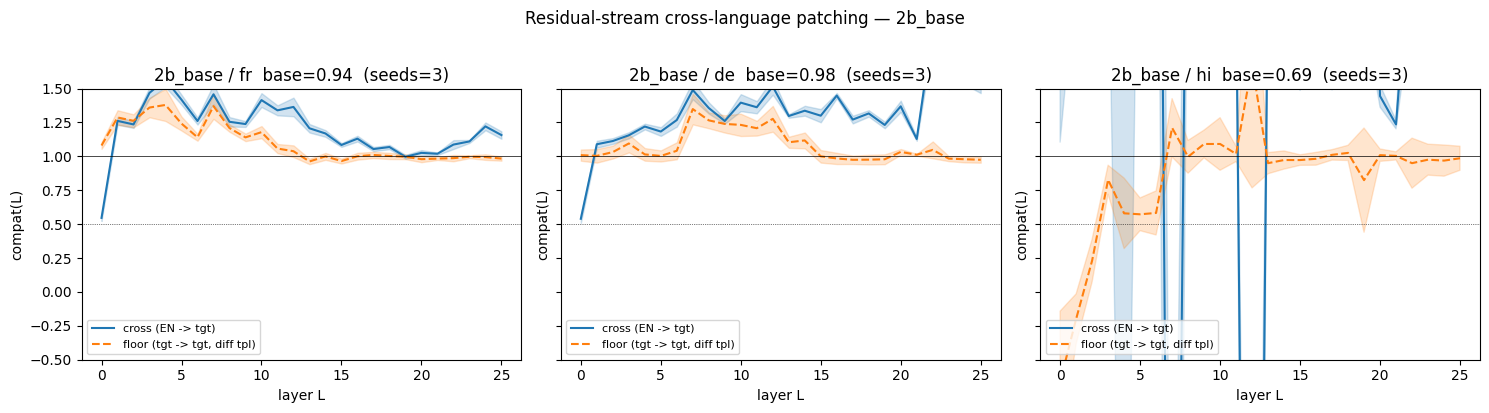

In [15]:
# RUN 1 — load 2B, self-test, then full sweep over FR / DE / HI (3 seeds each).
# When this completes: inspect the summary + plots, consult the decision rules
# above, THEN decide whether to run RUN 2 below. Do NOT run RUN 2 blindly.

MODEL_KEY = "2b_base"
model, tok = load_model(MODEL_KEY)

# log any Exp14 cache we happen to have for provenance
_ = load_exp14_cache(MODEL_KEY)

# Quick HI-name diagnostic (does not block anything)
_ = hi_name_diagnostic(tok)

# Mandatory self-test — STOP on failure
ok, _compats = self_test(model, tok)
assert ok, "SELF-TEST FAILED — hook is broken. STOP before running the sweep."

for lang in TARGET_LANGS:
    for seed in SEEDS:
        run_one(model, tok, MODEL_KEY, lang, seed)

print("\n=========== 2B SUMMARY ===========")
print_summary_table(model_keys=[MODEL_KEY])
plot_model(MODEL_KEY, TARGET_LANGS)

free_model(model)

## RUN 2 — 9B base, 9B-it, 27B-it (only after inspecting RUN 1)

[load] 9b_base  <-  /home/models/gemma-2-9b


Loading weights: 100%|██████████| 464/464 [00:01<00:00, 270.64it/s]


[load] 9b_base ready in 2.7s  n_layers=42  d_model=3584
[exp14 cache] not found at exp14_results/9b_base.json — building prompts fresh (OK)
[self-test] prompt = 'When Daniel and Mark went to the store, Daniel gave a drink to'
[self-test] clean logit-diff = +4.7500
  L=  0  patched=+4.7500  ablated=+2.5000  compat=+1.0000  ok=True
  L= 21  patched=+4.7500  ablated=-0.7500  compat=+1.0000  ok=True
  L= 41  patched=+4.7500  ablated=+0.0000  compat=+1.0000  ok=True
[self-test] all_ok = True
[baseline] 9b_base fr: EN=1.000  target=1.000  (target >= 0.75 required for TRUSTED)
[cross 9b_base fr s0] 20/120  rate=0.34/s  eta=291s
[cross 9b_base fr s0] 40/120  rate=0.35/s  eta=231s
[cross 9b_base fr s0] 60/120  rate=0.35/s  eta=173s
[cross 9b_base fr s0] 80/120  rate=0.35/s  eta=115s
[cross 9b_base fr s0] 100/120  rate=0.35/s  eta=58s
[cross 9b_base fr s0] 120/120  rate=0.35/s  eta=0s
[floor 9b_base fr s0] 20/120  rate=0.72/s  eta=140s
[floor 9b_base fr s0] 40/120  rate=0.72/s  eta=112s
[floor 9

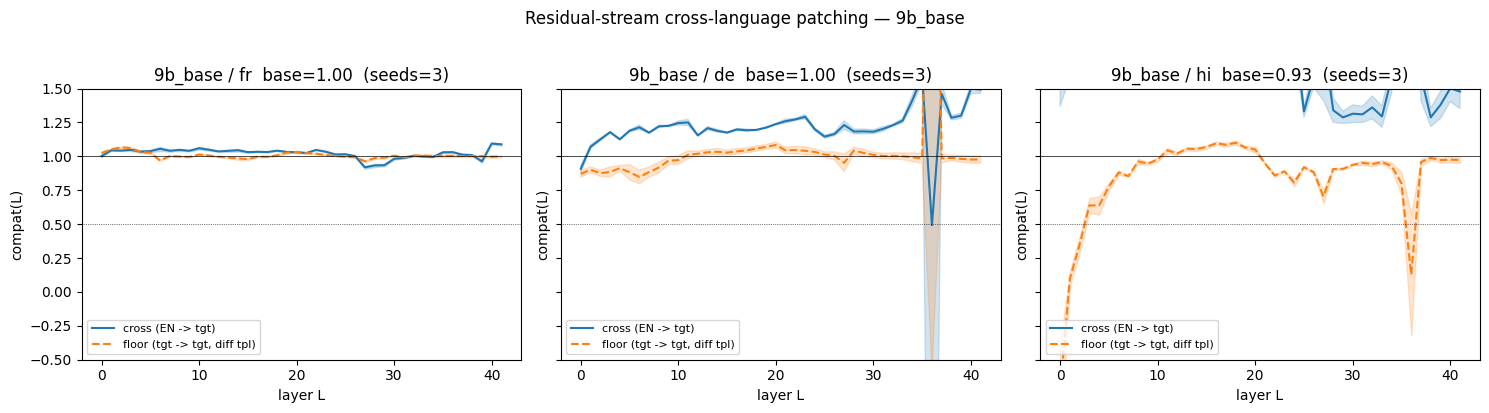

[load] 9b_it  <-  /home/models/gemma-2-9b-it


Loading weights: 100%|██████████| 464/464 [00:02<00:00, 219.10it/s]


[load] 9b_it ready in 3.1s  n_layers=42  d_model=3584
[exp14 cache] not found at exp14_results/9b_it.json — building prompts fresh (OK)
[self-test] prompt = 'When Daniel and Mark went to the store, Daniel gave a drink to'
[self-test] clean logit-diff = +5.7500
  L=  0  patched=+5.7500  ablated=+2.1250  compat=+1.0000  ok=True
  L= 21  patched=+5.7500  ablated=-0.6875  compat=+1.0000  ok=True
  L= 41  patched=+5.7500  ablated=+0.0000  compat=+1.0000  ok=True
[self-test] all_ok = True
[baseline] 9b_it fr: EN=1.000  target=1.000  (target >= 0.75 required for TRUSTED)
[cross 9b_it fr s0] 20/120  rate=0.68/s  eta=147s
[cross 9b_it fr s0] 40/120  rate=0.69/s  eta=116s
[cross 9b_it fr s0] 60/120  rate=0.69/s  eta=87s
[cross 9b_it fr s0] 80/120  rate=0.69/s  eta=58s
[cross 9b_it fr s0] 100/120  rate=0.69/s  eta=29s
[cross 9b_it fr s0] 120/120  rate=0.69/s  eta=0s
[floor 9b_it fr s0] 20/120  rate=0.70/s  eta=143s
[floor 9b_it fr s0] 40/120  rate=0.69/s  eta=115s
[floor 9b_it fr s0] 60/120  rate

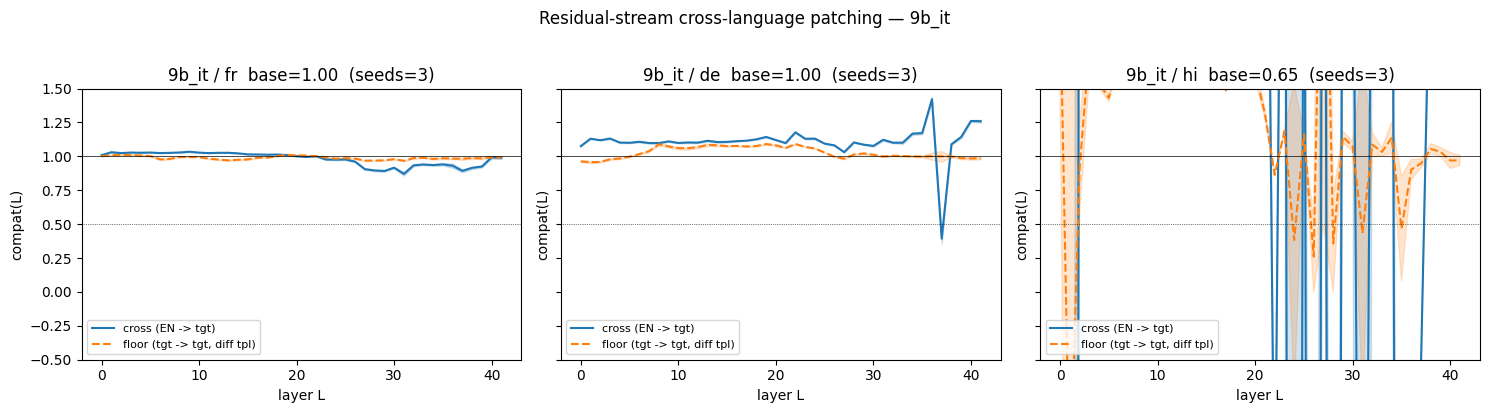

[load] 27b_it  <-  /home/models/gemma-2-27b-it


Loading weights: 100%|██████████| 508/508 [00:05<00:00, 84.99it/s]


[load] 27b_it ready in 7.0s  n_layers=46  d_model=4608
[exp14 cache] not found at exp14_results/27b_it.json — building prompts fresh (OK)
[self-test] prompt = 'When Daniel and Mark went to the store, Daniel gave a drink to'
[self-test] clean logit-diff = +7.5000
  L=  0  patched=+7.5000  ablated=+2.8750  compat=+1.0000  ok=True
  L= 23  patched=+7.5000  ablated=+1.3125  compat=+1.0000  ok=True
  L= 45  patched=+7.5000  ablated=+0.0000  compat=+1.0000  ok=True
[self-test] all_ok = True
[baseline] 27b_it fr: EN=1.000  target=1.000  (target >= 0.75 required for TRUSTED)
[cross 27b_it fr s0] 20/120  rate=0.38/s  eta=266s
[cross 27b_it fr s0] 40/120  rate=0.38/s  eta=212s
[cross 27b_it fr s0] 60/120  rate=0.38/s  eta=159s
[cross 27b_it fr s0] 80/120  rate=0.38/s  eta=106s
[cross 27b_it fr s0] 100/120  rate=0.38/s  eta=53s
[cross 27b_it fr s0] 120/120  rate=0.38/s  eta=0s
[floor 27b_it fr s0] 20/120  rate=0.38/s  eta=266s
[floor 27b_it fr s0] 40/120  rate=0.38/s  eta=213s
[floor 27b_it fr s0

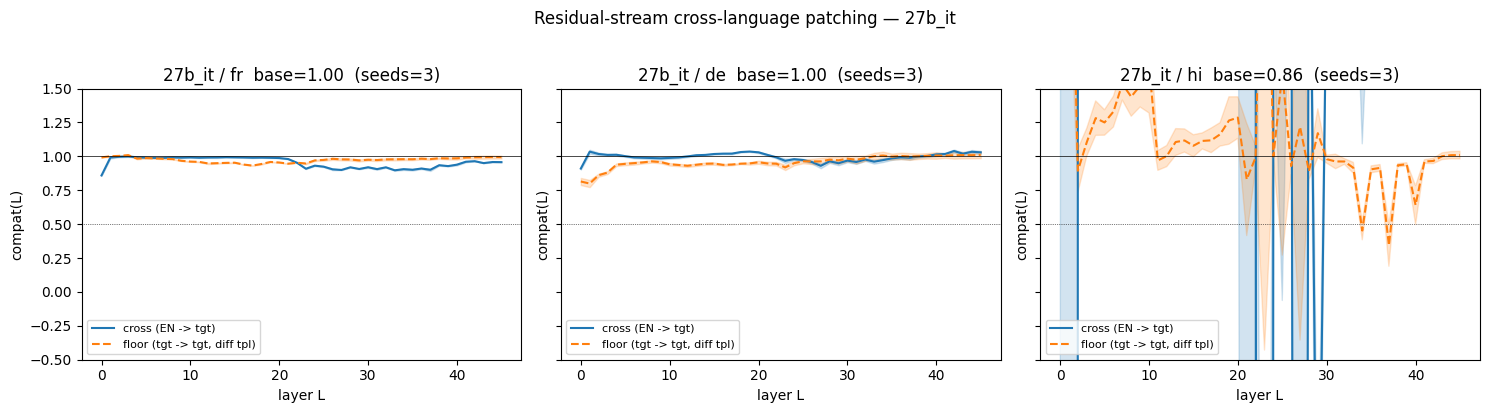


=========== FULL CROSS-SCALE SUMMARY ===========

2b_base / fr  [UNTRUSTED]  n_layers=26  n_seeds=3  baseline_en=1.00  baseline_target=0.94
  depth_of_split (cross < 0.5):  none (never < 0.5)
  L           :       0        6       13       19       25
  cross compat:  +0.546   +1.261   +1.207   +0.997   +1.157
  floor compat:  +1.080   +1.141   +0.962   +0.997   +0.984
  !! floor outside [0.9, 1.1] at L=[6] — cross at those L is UNINTERPRETABLE

2b_base / de  [UNTRUSTED]  n_layers=26  n_seeds=3  baseline_en=1.00  baseline_target=0.98
  depth_of_split (cross < 0.5):  none (never < 0.5)
  L           :       0        6       13       19       25
  cross compat:  +0.540   +1.268   +1.298   +1.232   +1.500
  floor compat:  +1.009   +1.041   +1.104   +0.979   +0.975
  !! floor outside [0.9, 1.1] at L=[13] — cross at those L is UNINTERPRETABLE

2b_base / hi  [UNTRUSTED]  n_layers=26  n_seeds=3  baseline_en=1.00  baseline_target=0.69
  depth_of_split (cross < 0.5):  7
  L           :       0

In [16]:
# RUN 2 — ONLY after inspecting RUN 1. The resume logic (per-seed cache files)
# means interrupting mid-run and restarting is safe: completed (model, lang, seed)
# cells reload from disk, so a Python exception on seed 2 of 27B does not cost
# the earlier work.

for MODEL_KEY in ["9b_base", "9b_it", "27b_it"]:
    model, tok = load_model(MODEL_KEY)

    _ = load_exp14_cache(MODEL_KEY)

    ok, _ = self_test(model, tok)
    if not ok:
        print(f"[WARNING] self-test failed on {MODEL_KEY} — skipping its sweep")
        free_model(model)
        continue

    for lang in TARGET_LANGS:
        for seed in SEEDS:
            run_one(model, tok, MODEL_KEY, lang, seed)

    print(f"\n=========== {MODEL_KEY} SUMMARY ===========")
    print_summary_table(model_keys=[MODEL_KEY])
    plot_model(MODEL_KEY, TARGET_LANGS)
    free_model(model)

print("\n=========== FULL CROSS-SCALE SUMMARY ===========")
print_summary_table()